## Importing pandas and loading the dataset

In [2]:
import pandas as pd
df = pd.read_csv('wine_quality_final.csv', encoding='latin1')
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (5320, 15)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red,Medium (5â6),9â10
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red,Medium (5â6),9â10
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red,Medium (5â6),9â10
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10


## Inspecting the dataset

In [3]:
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
quality_band             object
alcohol_band             object
dtype: object

In [4]:
df.describe

<bound method NDFrame.describe of       fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
0               7.4              0.70         0.00             1.9      0.076   
1               7.8              0.88         0.00             2.6      0.098   
2               7.8              0.76         0.04             2.3      0.092   
3              11.2              0.28         0.56             1.9      0.075   
4               7.4              0.66         0.00             1.8      0.075   
...             ...               ...          ...             ...        ...   
5315            6.2              0.21         0.29             1.6      0.039   
5316            6.6              0.32         0.36             8.0      0.047   
5317            6.5              0.24         0.19             1.2      0.041   
5318            5.5              0.29         0.30             1.1      0.022   
5319            6.0              0.21         0.38             0.8      0.0

## Selecting Columns

In [5]:
df["alcohol"].head()

0    9.4
1    9.8
2    9.8
3    9.8
4    9.4
Name: alcohol, dtype: float64

## Selecting rows with iloc

In [8]:
display(df.iloc[1])

fixed_acidity                      7.8
volatile_acidity                  0.88
citric_acid                        0.0
residual_sugar                     2.6
chlorides                        0.098
free_sulfur_dioxide               25.0
total_sulfur_dioxide              67.0
density                         0.9968
ph                                 3.2
sulphates                         0.68
alcohol                            9.8
quality                              5
wine_type                          Red
quality_band            Medium (5â6)
alcohol_band                    9â10
Name: 1, dtype: object

## Checking and removing duplicates

In [14]:
print ("duplicates before:",
       df.duplicated().sum())

duplicates before: 0


In [18]:
print ("duplicates after:",
       df.duplicated().sum())

duplicates after: 0


In [17]:
df = df.drop_duplicates().reset_index(drop=True)
print("New shape:",df.shape)

New shape: (5320, 15)


## Convert to data types

In [19]:
pd.to_numeric(...,errors="coerce")

Ellipsis

In [21]:
df["alcohol"]=pd.to_numeric(df["alcohol"],errors="coerce")

## Standardize Text

In [23]:
df["wine_type"]=df["wine_type"].str.strip().str.title()
df["wine_type"].value_counts()

wine_type
White    3961
Red      1359
Name: count, dtype: int64

## Handle missing values

In [25]:
df.isna().sum()

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
quality_band            0
alcohol_band            0
dtype: int64

In [26]:
df.dropna()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Red,Medium (5â6),9â10
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,Red,Medium (5â6),9â10
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,Red,Medium (5â6),9â10
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,Red,Medium (5â6),9â10
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4,5,Red,Medium (5â6),9â10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5315,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,White,Medium (5â6),11â12
5316,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,White,Medium (5â6),9â10
5317,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,White,Medium (5â6),9â10
5318,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,White,High (7â9),>12


## Create New Calculated Columns

New variables can be calculated from existing columns.

Here:

**Total Acidity = Fixed Acidity + Volatile Acidity**

We also calculate the proportion of free sulfur dioxide relative to total sulfur dioxide.

In [51]:
df["total_acidity"] = df["fixed_acidity"] + df["volatile_acidity"]

df["free_so2_ratio"] = (
    df["free_sulfur_dioxide"] / df["total_sulfur_dioxide"]
)

df[["fixed_acidity", "volatile_acidity", "total_acidity", "free_so2_ratio"]].head()

,fixed_acidity,volatile_acidity,total_acidity,free_so2_ratio
0,7.4,0.70,8.10,0.323529
1,7.8,0.88,8.68,0.373134
2,7.8,0.76,8.56,0.277778
3,11.2,0.28,11.48,0.283333
4,7.4,0.66,8.06,0.325000


In [27]:
df[
    (df["wine_type"] == "Red") &
    (df["alcohol"] > 10)
].head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band
8,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,Red,Medium (5â6),10â11
14,8.5,0.280,0.56,1.8,0.092,35.0,103.0,0.9969,3.30,0.75,10.5,7,Red,High (7â9),10â11
27,6.7,0.675,0.07,2.4,0.089,17.0,82.0,0.9958,3.35,0.54,10.1,5,Red,Medium (5â6),10â11
28,6.9,0.685,0.00,2.5,0.105,22.0,37.0,0.9966,3.46,0.57,10.6,6,Red,Medium (5â6),10â11
33,7.8,0.600,0.14,2.4,0.086,3.0,15.0,0.9975,3.42,0.60,10.8,6,Red,Medium (5â6),10â11


In [28]:
wine_details = pd.DataFrame({
    "wine_type": ["Red", "White"],
    "serving_temperature": ["15-18°C", "7-12°C"],
    "category": ["Red Wine", "White Wine"]
})

wine_details


,wine_type,serving_temperature,category
0,Red,15-18°C,Red Wine
1,White,7-12°C,White Wine


In [30]:
df["total_acidity"] = df["fixed_acidity"] + df["volatile_acidity"]

df["free_so2_ratio"] = (
    df["free_sulfur_dioxide"] / df["total_sulfur_dioxide"]
)

df[["fixed_acidity", "volatile_acidity", "total_acidity", "free_so2_ratio"]].head()


,fixed_acidity,volatile_acidity,total_acidity,free_so2_ratio
0,7.4,0.70,8.10,0.323529
1,7.8,0.88,8.68,0.373134
2,7.8,0.76,8.56,0.277778
3,11.2,0.28,11.48,0.283333
4,7.4,0.66,8.06,0.325000


## Filtering and Querying

Boolean indexing selects rows that satisfy a condition.

- `&` means **AND**
- `|` means **OR**

When combining conditions, place each condition inside parentheses.


In [31]:
# Red wines with alcohol greater than 10
df[
    (df["wine_type"] == "Red") &
    (df["alcohol"] > 10)
].head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band,total_acidity,free_so2_ratio
8,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,Red,Medium (5â6),10â11,8.000,0.166667
14,8.5,0.280,0.56,1.8,0.092,35.0,103.0,0.9969,3.30,0.75,10.5,7,Red,High (7â9),10â11,8.780,0.339806
27,6.7,0.675,0.07,2.4,0.089,17.0,82.0,0.9958,3.35,0.54,10.1,5,Red,Medium (5â6),10â11,7.375,0.207317
28,6.9,0.685,0.00,2.5,0.105,22.0,37.0,0.9966,3.46,0.57,10.6,6,Red,Medium (5â6),10â11,7.585,0.594595
33,7.8,0.600,0.14,2.4,0.086,3.0,15.0,0.9975,3.42,0.60,10.8,6,Red,Medium (5â6),10â11,8.400,0.200000


In [32]:
# Red wines OR wines with alcohol greater than 12
df[
    (df["wine_type"] == "Red") |
    (df["alcohol"] > 12)
].head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band,total_acidity,free_so2_ratio
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10,8.10,0.323529
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red,Medium (5â6),9â10,8.68,0.373134
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red,Medium (5â6),9â10,8.56,0.277778
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red,Medium (5â6),9â10,11.48,0.283333
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10,8.06,0.325000


## Using query

In [33]:
df.query("alcohol > 10").head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band,total_acidity,free_so2_ratio
8,7.5,0.500,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,Red,Medium (5â6),10â11,8.000,0.166667
14,8.5,0.280,0.56,1.8,0.092,35.0,103.0,0.9969,3.30,0.75,10.5,7,Red,High (7â9),10â11,8.780,0.339806
27,6.7,0.675,0.07,2.4,0.089,17.0,82.0,0.9958,3.35,0.54,10.1,5,Red,Medium (5â6),10â11,7.375,0.207317
28,6.9,0.685,0.00,2.5,0.105,22.0,37.0,0.9966,3.46,0.57,10.6,6,Red,Medium (5â6),10â11,7.585,0.594595
33,7.8,0.600,0.14,2.4,0.086,3.0,15.0,0.9975,3.42,0.60,10.8,6,Red,Medium (5â6),10â11,8.400,0.200000


## Sorting

In [34]:
df.sort_values("quality", ascending=False).head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band,total_acidity,free_so2_ratio
2053,7.4,0.24,0.36,2.0,0.031,27.0,139.0,0.99055,3.28,0.48,12.5,9,White,High (7â9),>12,7.64,0.194245
2047,6.6,0.36,0.29,1.6,0.021,24.0,85.0,0.98965,3.41,0.61,12.4,9,White,High (7â9),>12,6.96,0.282353
2012,9.1,0.27,0.45,10.6,0.035,28.0,124.0,0.99700,3.20,0.46,10.4,9,White,High (7â9),10â11,9.37,0.225806
2091,6.9,0.36,0.34,4.2,0.018,57.0,119.0,0.98980,3.28,0.36,12.7,9,White,High (7â9),>12,7.26,0.478992
2712,7.1,0.26,0.49,2.2,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,9,White,High (7â9),>12,7.36,0.274336


## Grouping and Aggregation

`groupby()` divides records into groups.

`agg()` can calculate several summary statistics for each group at the same time.

Here, we summarize alcohol levels for Red and White wines.

In [35]:
df.groupby("wine_type")["alcohol"].agg(
    ["mean", "min", "max", "count"]
)


,mean,min,max,count
wine_type,,,,
Red,10.432315,8.4,14.9,1359
White,10.589358,8.0,14.2,3961


## Create a Second Dataset for Merging

To demonstrate merging, we create a small DataFrame containing additional information about Red and White wines.

The common column between the two DataFrames is `wine_type`.

In [36]:
wine_details = pd.DataFrame({
    "wine_type": ["Red", "White"],
    "serving_temperature": ["15-18°C", "7-12°C"],
    "category": ["Red Wine", "White Wine"]
})

wine_details


,wine_type,serving_temperature,category
0,Red,15-18°C,Red Wine
1,White,7-12°C,White Wine


## Merge the Two DataFrames

`pd.merge()` performs an SQL-style join.

`how="left"` means:
- keep every row from the left DataFrame (`df`),
- add matching information from `wine_details` where `wine_type` agrees.

In [37]:
merged_df = pd.merge(
    df,
    wine_details,
    on="wine_type",
    how="left"
)

merged_df.head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,quality_band,alcohol_band,total_acidity,free_so2_ratio,serving_temperature,category
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10,8.10,0.323529,15-18°C,Red Wine
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red,Medium (5â6),9â10,8.68,0.373134,15-18°C,Red Wine
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red,Medium (5â6),9â10,8.56,0.277778,15-18°C,Red Wine
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red,Medium (5â6),9â10,11.48,0.283333,15-18°C,Red Wine
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Red,Medium (5â6),9â10,8.06,0.325000,15-18°C,Red Wine


# Matplotlib

## What is Matplotlib?

**Matplotlib** is a Python library used to create charts and graphs.

We continue using the cleaned **Wine Quality DataFrame (`df`)** from the Pandas section.


## Bar Chart — Average Alcohol by Wine Type

A bar chart compares values across categories.

Here we compare the average alcohol level of Red and White wines.

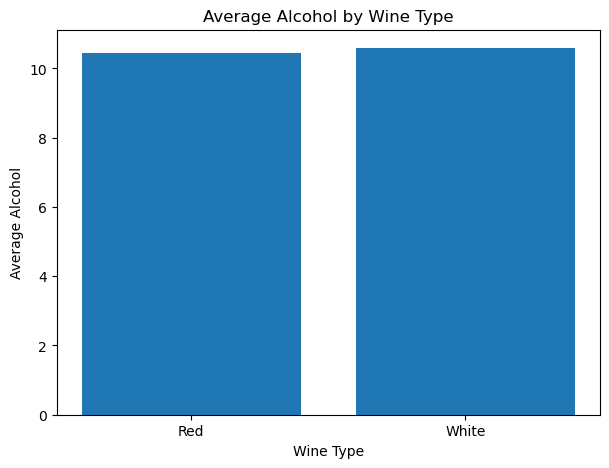

In [40]:
import matplotlib.pyplot as plt
average_alcohol = df.groupby("wine_type")["alcohol"].mean()

plt.figure(figsize=(7, 5))
plt.bar(average_alcohol.index, average_alcohol.values)
plt.title("Average Alcohol by Wine Type")
plt.xlabel("Wine Type")
plt.ylabel("Average Alcohol")
plt.show()

### Interpretation

Each bar represents a wine type. The taller bar represents the group with the higher average alcohol level in this dataset.

## Histogram — Alcohol Distribution

A histogram shows how numerical values are distributed across intervals.


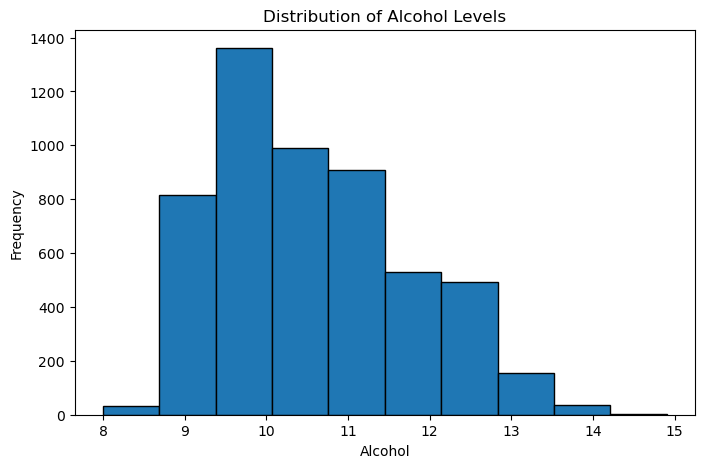

In [53]:
plt.figure(figsize=(8, 5))
plt.hist(df["alcohol"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of Alcohol Levels")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")
plt.show()

## Scatter Plot — Alcohol vs Quality

A scatter plot helps examine the relationship between two numerical variables.

Each point represents one wine record.

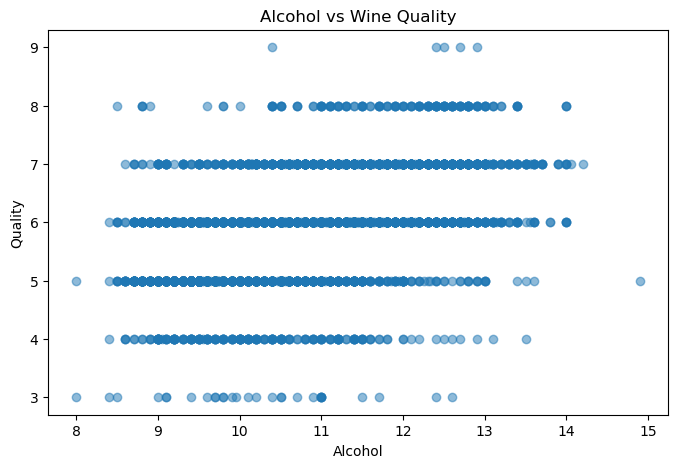

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(df["alcohol"], df["quality"], alpha=0.5)
plt.title("Alcohol vs Wine Quality")
plt.xlabel("Alcohol")
plt.ylabel("Quality")
plt.show()


## Box Plot — Alcohol by Wine Type

A box plot summarizes the distribution of a numerical variable across categories.

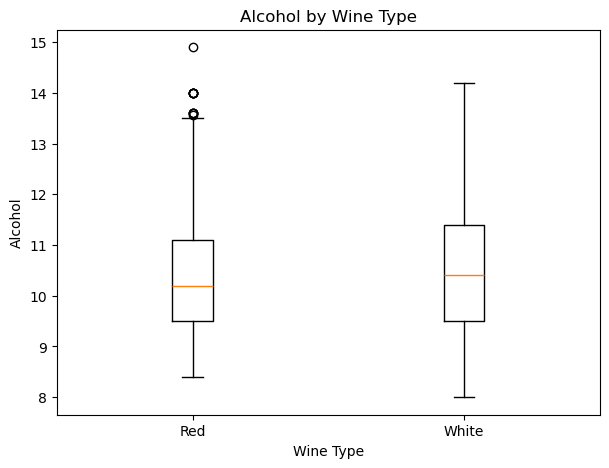

In [42]:
red_alcohol = df.loc[df["wine_type"] == "Red", "alcohol"].dropna()
white_alcohol = df.loc[df["wine_type"] == "White", "alcohol"].dropna()

plt.figure(figsize=(7, 5))
plt.boxplot(
    [red_alcohol, white_alcohol],
    tick_labels=["Red", "White"]
)
plt.title("Alcohol by Wine Type")
plt.xlabel("Wine Type")
plt.ylabel("Alcohol")
plt.show()


# Seaborn

## What is Seaborn?

**Seaborn** is a statistical visualization library built on Matplotlib.

It works directly with Pandas DataFrames and provides convenient functions for exploring distributions, categories, relationships, and correlations.


## Histogram with KDE — Alcohol

`histplot()` shows the distribution of alcohol values.

`kde=True` adds a smooth density curve.


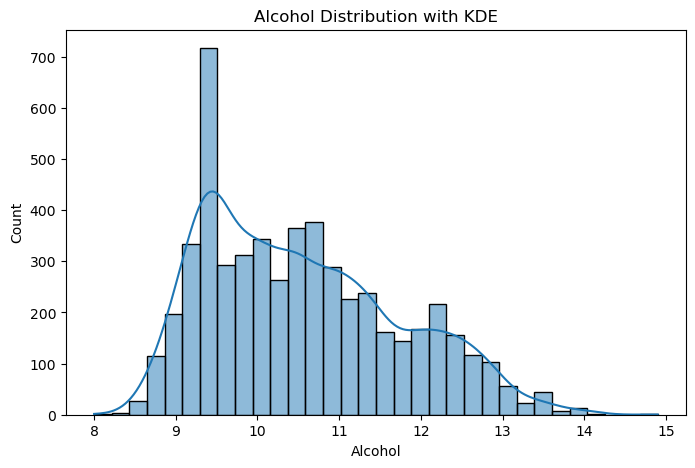

In [43]:
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="alcohol", kde=True)
plt.title("Alcohol Distribution with KDE")
plt.xlabel("Alcohol")
plt.show()

## Box Plot — Alcohol by Wine Type

This chart compares alcohol distributions for Red and White wines.


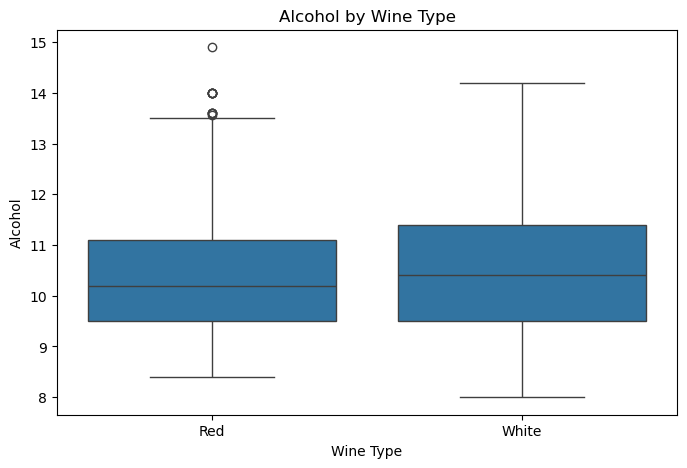

In [44]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="wine_type", y="alcohol")
plt.title("Alcohol by Wine Type")
plt.xlabel("Wine Type")
plt.ylabel("Alcohol")
plt.show()

## Scatter Plot — Alcohol vs Quality by Wine Type

`hue="wine_type"` separates Red and White wines visually on the same scatter plot.


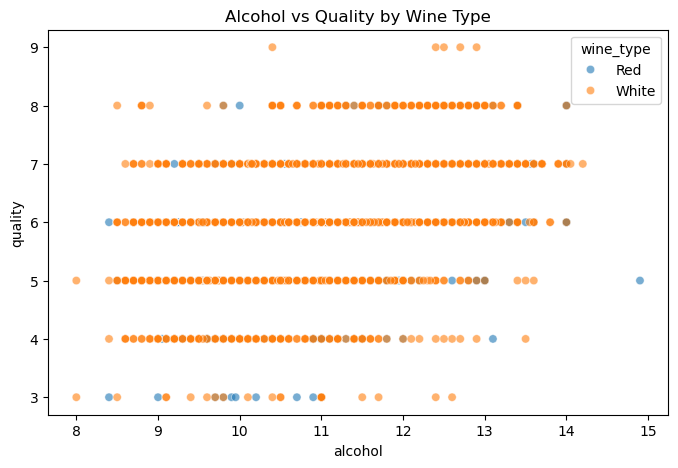

In [45]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="alcohol",
    y="quality",
    hue="wine_type",
    alpha=0.6
)
plt.title("Alcohol vs Quality by Wine Type")
plt.show()

## Correlation Heatmap

Correlation measures the strength and direction of a linear relationship between numerical variables.

Only numerical columns are included in the correlation matrix.


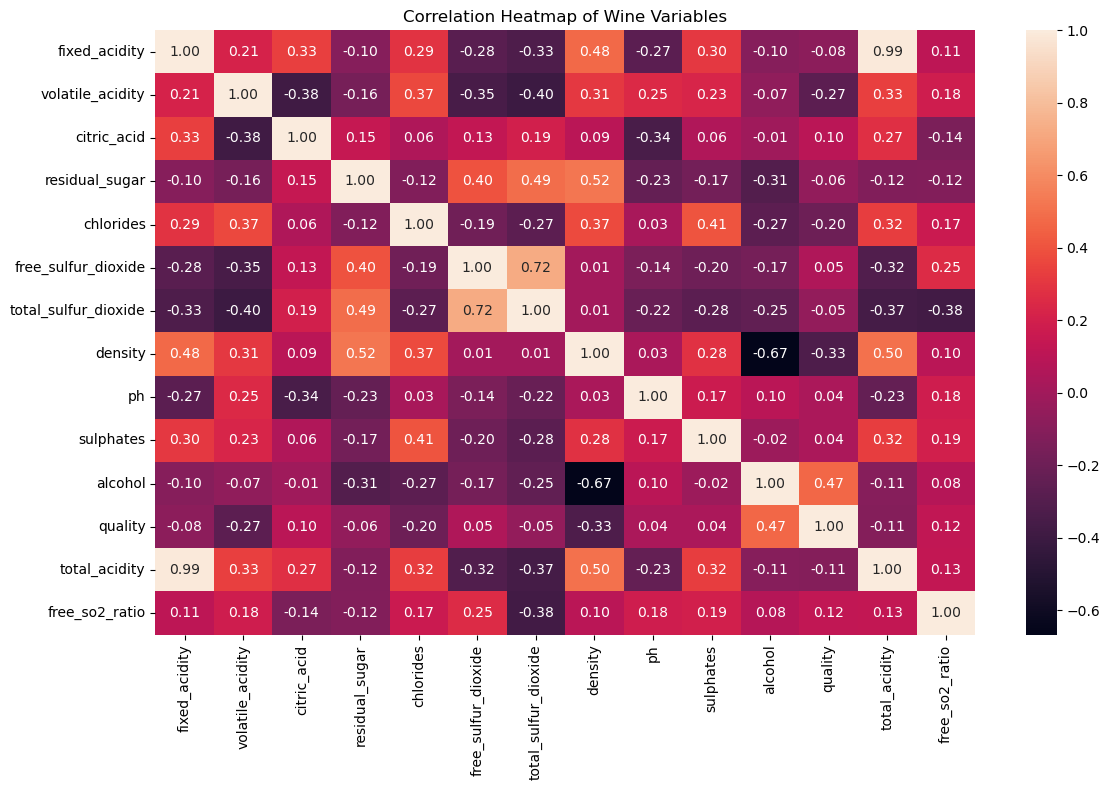

In [46]:
numeric_data = df.select_dtypes(include="number")
correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Wine Variables")
plt.tight_layout()
plt.show()

# Scikit-learn

## What is Scikit-learn?

**Scikit-learn** is a Python machine-learning library.

We continue using the same cleaned **Wine Quality dataset (`df`)**.

Our task is **classification** because the model will predict the discrete wine `quality` score.

The workflow is:

**Choose Features and Target → Split Data → Train Model → Predict → Evaluate**


## Define the Features (`X`) and Target (`y`)

Instead of selecting columns automatically, we explicitly list the exact predictor columns used by the model.

### Features (`X`)
The model uses these 11 original numerical wine measurements:

1. `fixed_acidity`
2. `volatile_acidity`
3. `citric_acid`
4. `residual_sugar`
5. `chlorides`
6. `free_sulfur_dioxide`
7. `total_sulfur_dioxide`
8. `density`
9. `ph`
10. `sulphates`
11. `alcohol`

### Target (`y`)
- `quality`

`wine_type`, `quality_band`, and `alcohol_band` are not included as model features. The calculated Pandas columns are also excluded so that the model uses the original numerical wine measurements.

In [47]:
X = df[[
    "fixed_acidity",
    "volatile_acidity",
    "citric_acid",
    "residual_sugar",
    "chlorides",
    "free_sulfur_dioxide",
    "total_sulfur_dioxide",
    "density",
    "ph",
    "sulphates",
    "alcohol"
]]

y = df["quality"]

X.head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4


In [48]:
y.head()

0    5
1    5
2    5
3    6
4    5
Name: quality, dtype: int64

## Confirm the Machine-Learning Data

Before splitting the dataset, confirm the number of records and features and check the quality classes.


In [49]:
print("X shape:", X.shape)
print("y shape:", y.shape)

y.value_counts().sort_index()


X shape: (5320, 11)
y shape: (5320,)


quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

## Split into Training and Testing Data

`train_test_split()` divides the data into:

- **80% training data** — used to teach the model.
- **20% testing data** — used to evaluate the trained model.

`random_state=42` makes the split reproducible.

`stratify=y` helps preserve the distribution of the quality classes in both sets.

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (4256, 11)
X_test: (1064, 11)
y_train: (4256,)
y_test: (1064,)


## Train a Decision Tree Classifier

A **Decision Tree Classifier** learns decision rules from the training data.

`X_train` contains the 11 wine measurements and `y_train` contains their known quality scores.


In [58]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Make Predictions

The trained model now predicts wine quality for the unseen records in `X_test`.

The predictions are stored in `y_pred`.

In [60]:
y_pred = model.predict(X_test)

y_pred[:10]

array([6, 7, 6, 7, 6, 5, 5, 5, 6, 5])

## Compare Actual and Predicted Quality

This table places the true quality score beside the model's predicted quality score.

In [61]:
comparison = pd.DataFrame({
    "Actual_Quality": y_test.to_numpy(),
    "Predicted_Quality": y_pred
})

comparison.head(10)

,Actual_Quality,Predicted_Quality
0,5,6
1,6,7
2,6,6
3,7,7
4,5,6
5,4,5
6,6,5
7,4,5
8,6,6
9,6,5


## Evaluate the Model

We use:

- **Accuracy** — proportion of all predictions that are correct.
- **Precision** — how many predictions for a class are correct.
- **Recall** — how many actual records of a class are correctly found.
- **F1-score** — balance between precision and recall.

In [59]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print()
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.525

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00        41
           5       0.57      0.62      0.59       350
           6       0.52      0.62      0.57       465
           7       0.43      0.31      0.36       171
           8       0.00      0.00      0.00        30
           9       0.00      0.00      0.00         1

    accuracy                           0.53      1064
   macro avg       0.22      0.22      0.22      1064
weighted avg       0.48      0.53      0.50      1064

